# GBST-BERT on human DNA — the complete pipeline

**Does a learned tokenizer help a small DNA language model?**
This notebook goes through every step of the project, explains it, runs it, and shows the results:

| Part | What happens | Runs here by default |
|---|---|---|
| 1 | Setup: switches, paths, GPU | yes |
| 2 | Data: the human genome (hg38) and its training / validation / test split | yes (≈2 min) |
| 3 | Tokenizer and masking: how DNA becomes numbers, and the training task | yes |
| 4 | The model: GBST-BERT and the control model Transformer++ | yes |
| 5 | Pretraining: learning rate check and full training (10.5 billion bases per model) | saved runs (re-run: switch) |
| 6 | Final test of the pretrained models (2,048 unseen sequences) | **yes, re-computed** |
| 7 | Inside the model: what GBST learned, and where the model is confident | **yes, re-computed** |
| 8 | Prediction tasks: 18 tasks of the Nucleotide Transformer benchmark, 10 repeats | one job re-run; all 384 saved runs analysed |
| 9 | Results tables and figures, compared with the Bio-xLSTM paper | yes |
| 10 | Summary | — |

**How to run it** (on `student07`):

```bash
source ~/envs/charna/bin/activate
cd ~/charna/dna-xlstm
jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.timeout=-1 \
    --ExecutePreprocessor.kernel_name=charna notebooks/GBST_BERT_full_pipeline.ipynb
```

With the default switches this takes about 30 minutes on one GPU (most of it is the re-run of one
fine-tuning job in Part 8). The two long steps, pretraining (≈1 day per model on 4 GPUs) and the
full benchmark (≈2 days on 4 GPUs), are run by the exact same scripts when their switch is set to
`True`; otherwise the notebook loads the results of the original runs from `outputs/`.

**Papers.** ChaRNABERT: Morales-Pastor et al. 2024, arXiv:2411.11808 (the model).
Bio-xLSTM: Schmidinger et al. 2024, arXiv:2411.04165 (pretraining protocol, benchmark protocol,
comparison values). Charformer: Tay et al. 2021, arXiv:2106.12672 (GBST).

## 1. Setup

**Switches.** Only these lines need changing. `GPU` must be a free GPU: on `student07` GPU 0
belongs to another user, so the project used GPUs 1–4 (check with `nvidia-smi`).

In [1]:
GPU = "1"                 # one free GPU for the steps that run inside this notebook
TRAIN_GPUS = "1,2,3,4"    # GPUs for the long runs (pretraining, full benchmark)

RUN_PRETRAINING = False   # True: pretrain both models again from scratch (≈1 day per model on 4 GPUs)
RUN_NT_BENCHMARK = False  # True: all 18 tasks × 2 models × 10 repeats again (≈2 days on 4 GPUs)
RUN_ONE_FINETUNE = True   # True: re-run one fine-tuning job (GBST-BERT, task H3, repeat 1; ≈16 min)

In [2]:
import os, sys, re, json, time, math, pathlib, subprocess, importlib.util, warnings
os.environ["CUDA_VISIBLE_DEVICES"] = GPU          # must be set before torch is imported
warnings.filterwarnings("ignore")

REPO = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
os.chdir(REPO)
sys.path.insert(0, str(REPO))
OUT = REPO / "notebooks" / "outputs"               # tables and figures made by this notebook
OUT.mkdir(parents=True, exist_ok=True)

# The repository's evaluation script also prepares the imports of the training code.
spec = importlib.util.spec_from_file_location("evaluate_mlm", REPO / "scripts_charna" / "evaluate_mlm.py")
evaluate_mlm = importlib.util.module_from_spec(spec)
spec.loader.exec_module(evaluate_mlm)

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from pyfaidx import Fasta
from IPython.display import display, Markdown

import gbst_bert                                    # the whole model in one file (repository root)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
FASTA = REPO / "data/hg38/hg38.ml.fa"
BED = REPO / "data/hg38/human-sequences.bed"
PRETRAIN = REPO / "outputs/pretrain/hg38"
NT_RESULTS = REPO / "outputs/downstream/nt_cv10_ep20"

# One look for every figure: blue = GBST-BERT, orange = Transformer++, green = paper models
BLUE, ORANGE, GREEN, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#a3a9b5"
TEXT, MUTED, GRID = "#1a1a1a", "#52514e", "#e4e3df"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 10.5, "axes.edgecolor": MUTED,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": GRID, "axes.axisbelow": True, "axes.titlelocation": "left",
                     "axes.titlesize": 12, "legend.frameon": False})
pd.set_option("display.precision", 4)

def save(fig, name):
    fig.savefig(OUT / f"{name}.png", bbox_inches="tight")
    fig.savefig(OUT / f"{name}.pdf", bbox_inches="tight")

def shell(cmd, log, cwd=REPO, env=None):
    # Run a shell command, write its output to a log file, and stop if it fails.
    start = time.time()
    with open(log, "w") as f:
        status = subprocess.run(["bash", "-c", cmd], cwd=cwd, env={**os.environ, **(env or {})},
                                stdout=f, stderr=subprocess.STDOUT).returncode
    print(f"finished in {(time.time() - start) / 60:.1f} min, exit code {status}, log: {log}")
    assert status == 0, f"command failed, see {log}"

print(f"repository: {REPO}")
print(f"torch {torch.__version__}, device: {DEVICE}"
      + (f" ({torch.cuda.get_device_name(0)}, physical GPU {GPU})" if DEVICE == "cuda" else ""))

[train_charna] placeholders for missing optional packages: mamba_ssm, flash_attn, causal_conv1d, selective_scan_cuda
[train_charna] CUDA_HOME not set; using /system/user/omohamed/envs/charna/lib64/python3.9/site-packages/nvidia/cuda_runtime (no compilation happens)


repository: /system/user/omohamed/charna/dna-xlstm
torch 2.2.0+cu121, device: cuda (NVIDIA GeForce RTX 2080 Ti, physical GPU 1)


## 2. Data: the human genome

The models learn from the human reference genome **hg38**, as prepared by the DNA-xLSTM
repository (`scripts_charna/download_data.sh`): chromosomes 1–22 and X. Unknown bases are
written `N`.

The repository's BED file lists **38,171 regions of 131,072 bases** with a label *train*,
*valid* or *test*. The data loader widens every region to **2²⁰ = 1,048,576 bases** around its
centre and cuts it into 1,024 pieces of **1,024 bases** — one training example each. Regions of
different splits never overlap, so test DNA is never seen in training.

**23 sequences, 3,031,042,417 bases in total; 119,818,347 unknown (N) = 4.0%.**

,regions,"examples of 1,024 bases",distinct bases (billion),share of the three
split,,,,
train,"34,021","34,837,504",2.332,81%
valid,"2,213","2,266,112",0.291,10%
test,"1,937","1,983,488",0.272,9%


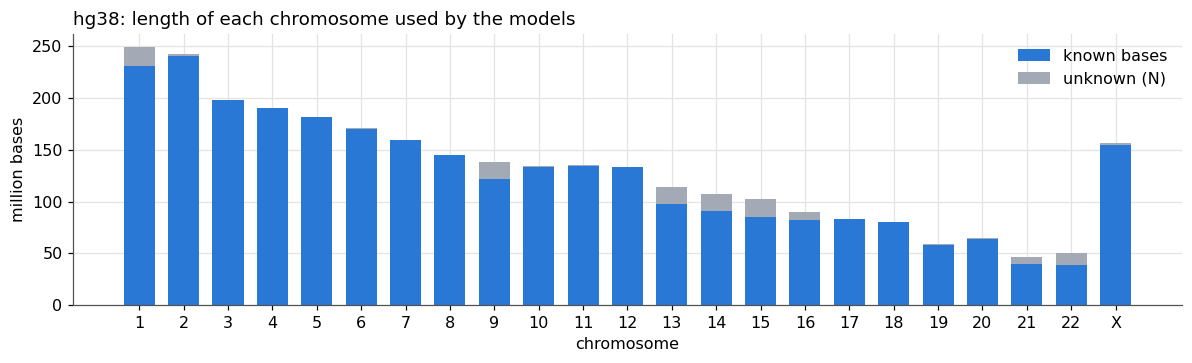

In [3]:
genome = Fasta(str(FASTA))
rows = []
for name in genome.keys():
    seq = str(genome[name])
    rows.append({"chromosome": name, "length": len(seq), "N": seq.count("N") + seq.count("n")})
chroms = pd.DataFrame(rows)
total, n_unknown = chroms.length.sum(), chroms.N.sum()
display(Markdown(f"**{len(chroms)} sequences, {total:,} bases in total; {n_unknown:,} unknown (N) = "
                 f"{100 * n_unknown / total:.1f}%.**"))

bed = pd.read_csv(BED, sep="\t", names=["chromosome", "start", "end", "split"])
half = (2 ** 20 - 131_072) // 2                       # widening on each side

def unique_bases(regions):
    # Number of distinct bases covered by the widened regions.
    covered = 0
    for chrom, group in regions.groupby("chromosome"):
        length = len(genome[chrom])
        intervals = sorted(zip((group.start - half).clip(lower=0), (group.end + half).clip(upper=length)))
        cur_start, cur_end = intervals[0]
        for s, e in intervals[1:]:
            if s <= cur_end:
                cur_end = max(cur_end, e)
            else:
                covered += cur_end - cur_start
                cur_start, cur_end = s, e
        covered += cur_end - cur_start
    return covered

splits = pd.DataFrame([{"split": s, "regions": int((bed.split == s).sum()),
                        "examples of 1,024 bases": int((bed.split == s).sum()) * 1024,
                        "distinct bases (billion)": unique_bases(bed[bed.split == s]) / 1e9}
                       for s in ["train", "valid", "test"]]).set_index("split")
splits["share of the three"] = splits["distinct bases (billion)"] / splits["distinct bases (billion)"].sum()
display(splits.style.format({"examples of 1,024 bases": "{:,}", "distinct bases (billion)": "{:.3f}",
                             "share of the three": "{:.0%}", "regions": "{:,}"}))

fig, ax = plt.subplots(figsize=(13, 3.2))
order = sorted(chroms.chromosome, key=lambda c: (c == "chrX", int(c[3:]) if c[3:].isdigit() else 99))
ch = chroms.set_index("chromosome").loc[order]
ax.bar(range(len(ch)), (ch.length - ch.N) / 1e6, color=BLUE, width=0.7, label="known bases")
ax.bar(range(len(ch)), ch.N / 1e6, bottom=(ch.length - ch.N) / 1e6, color=GREY, width=0.7, label="unknown (N)")
ax.set_xticks(range(len(ch)), [c[3:] for c in ch.index])
ax.set_ylabel("million bases"); ax.set_xlabel("chromosome")
ax.set_title("hg38: length of each chromosome used by the models"); ax.legend()
save(fig, "data_chromosomes"); plt.show()

## 3. Tokenizer and masking: the training task

The repository's tokenizer gives **one number per base**: A = 7, C = 8, G = 9, T = 10, N = 11
(0–6 are special tokens such as `[MASK]` = 3 and `[PAD]` = 4).

**Training task: masked language modelling (MLM)**, as in BERT and Bio-xLSTM. In each sequence
15% of the positions are chosen. Of these, 80% are replaced by `[MASK]`, 10% by a random token,
and 10% stay unchanged. The model must recover the original base at every chosen position from
the bases on both sides. The **loss** is the average cross-entropy over the chosen positions, in
nats: guessing among four bases at random gives ln 4 = 1.386; a perfect model gives 0.

In [4]:
example = str(genome["chr21"][33_045_056:33_045_116]).upper()
ids = gbst_bert.encode(example)
inputs, targets = gbst_bert.mask_for_mlm(ids[None].repeat(1, 1), generator=torch.Generator().manual_seed(3))
shown = lambda t: "".join("_" if int(i) == gbst_bert.MASK_ID else gbst_bert.ID_TO_TOKEN[int(i)][0]
                          if int(i) >= 7 else "?" for i in t)
print("DNA            ", example)
print("token numbers  ", ids[:12].tolist(), "...")
print("model input    ", shown(inputs[0]), "   (_ = [MASK])")
print("to predict     ", "".join(example[i] if targets[0, i] != gbst_bert.PAD_ID else "·" for i in range(len(example))))

# the proportions on a large batch
big = torch.full((256, 1024), gbst_bert.VOCAB["A"])
inp, tgt = gbst_bert.mask_for_mlm(big, generator=torch.Generator().manual_seed(0))
chosen = tgt != gbst_bert.PAD_ID
display(pd.DataFrame({"share": [chosen.float().mean().item(),
                                (inp[chosen] == gbst_bert.MASK_ID).float().mean().item(),
                                ((inp[chosen] != gbst_bert.MASK_ID) & (inp[chosen] != big[chosen])).float().mean().item(),
                                (inp[chosen] == big[chosen]).float().mean().item()]},
                     index=["positions chosen", "  of these: [MASK]", "  of these: random token",
                            "  of these: unchanged (or random = same)"]).style.format("{:.1%}"))

DNA             CATTGATTTTTAAATTAACTTTTCACTGTGGAATAATTCTAGATTCACAGAAAAGTTGCA
token numbers   [8, 7, 10, 10, 9, 7, 10, 10, 10, 10, 10, 7] ...
model input     C_T_G_TTTTTA_A?TAACTTTT_ACTG__GA_T_AT_CTAGATTCACAGAAAAGTTGCA    (_ = [MASK])
to predict      CA·T·A······A·T········C····TG··ATA··T······················


,share
positions chosen,15.0%
of these: [MASK],80.5%
of these: random token,8.5%
of these: unchanged (or random = same),11.0%


## 4. The model

**GBST-BERT** (ChaRNABERT, Sec. 3) has three parts:

1. **GBST tokenizer** (Gradient-Based Subword Tokenization). Each base gets a vector, a small
   sliding window (4 bases) mixes neighbouring bases, then for every position GBST forms
   candidate blocks of 1, 2, 3 and 4 bases that contain it (10 candidates), scores each block,
   and returns a score-weighted mix. The block weights are learned from the data, so the model
   decides itself how to "cut" the DNA, while keeping one vector per base.
2. **Encoder**: 4 Transformer blocks (width 256, 8 attention heads) that read in both directions,
   with rotary position encoding (RoPE), QK normalisation and SwiGLU feed-forward layers.
3. **Head**: a linear layer that scores A, C, G, T (and the special tokens) at every position.

**Control model: Transformer++** — the 2-million-parameter Transformer of the Bio-xLSTM paper
(Table A3), same width, depth and heads, with a plain lookup table instead of GBST. Comparing
the two shows what GBST adds.

The cell below builds both models with the repository's code, loads the final weights
(step 10,000), and checks that the one-file version `gbst_bert.py` gives exactly the same output.

In [5]:
def load_repo_model(run):
    # Model from the repository's training code, weights from the run's final checkpoint.
    model, step = evaluate_mlm.build_model(PRETRAIN / run, "last.ckpt")
    return model.to(DEVICE).eval(), step

MODELS = {"GBST-BERT": "full_charna_mlm", "Transformer++": "full_llama_mlm"}
if RUN_PRETRAINING:                                   # Part 5 writes the new runs under these names
    MODELS = {name: "notebook_" + run for name, run in MODELS.items()}

rows = []
for name, run in MODELS.items():
    model, step = load_repo_model(run)
    n = sum(p.numel() for p in model.parameters())
    if name == "GBST-BERT":
        n_tok = sum(p.numel() for p in model.backbone.gbst.parameters())
    else:   # the lookup table(s) of the plain Transformer
        n_tok = sum(p.numel() for mod in model.modules() if isinstance(mod, torch.nn.Embedding) for p in mod.parameters())
    rows.append({"model": name, "training steps": step, "parameters": n,
                 "of these: tokenizer / embedding": n_tok, "encoder blocks": 4, "width": 256})
    if name == "GBST-BERT":
        gbst_model = model
display(pd.DataFrame(rows).set_index("model").style.format({"parameters": "{:,}",
                                                           "of these: tokenizer / embedding": "{:,}"}))

gbst = gbst_model.backbone.gbst
parts = {"embedding (12 tokens × 256)": gbst.embedding, "depthwise convolution (kernel 4)": gbst.conv,
         "pointwise layer (256 × 256)": gbst.pointwise, "block scorer (256 → 1)": gbst.scorer}
display(pd.DataFrame({"parameters": {k: sum(p.numel() for p in m.parameters()) for k, m in parts.items()}})
        .style.format("{:,}").set_caption("GBST, part by part"))

# the one-file version must reproduce the training code exactly
one_file = gbst_bert.load_pretrained(PRETRAIN / MODELS["GBST-BERT"] / "checkpoints/last.ckpt").to(DEVICE)
x = gbst_bert.encode(str(genome["chr21"][33_045_056:33_046_080]))[None].to(DEVICE)
with torch.no_grad():
    difference = (one_file(x) - gbst_model(x).logits).abs().max().item()
print(f"gbst_bert.py vs training code on 1,024 bases of chr21: largest difference in output = {difference:.1e}")
assert difference < 1e-4

,training steps,parameters,of these: tokenizer / embedding,encoder blocks,width
model,,,,,
GBST-BERT,10000,"2,107,392","70,144",4,256
Transformer++,10000,"2,036,992","3,072",4,256


,parameters
embedding (12 tokens × 256),"3,072"
depthwise convolution (kernel 4),"1,280"
pointwise layer (256 × 256),"65,536"
block scorer (256 → 1),256


gbst_bert.py vs training code on 1,024 bases of chr21: largest difference in output = 0.0e+00


## 5. Pretraining

**Protocol** — the short-context pretraining of Bio-xLSTM (App. C.5, Tables A3–A4), identical
for both models:

| Setting | Value |
|---|---|
| Data | hg38 training split, random 1,024-base pieces, reverse-complement augmentation |
| Batch | 1,024 sequences × 1,024 bases = 2²⁰ bases per step (4 GPUs × 32 sequences × 8 accumulation steps) |
| Length | 10,000 steps = **10.5 billion bases** |
| Optimiser | AdamW (β = 0.9, 0.95), weight decay 0.1, gradient clipping 1.0 |
| Schedule | linear warm-up for 1,000 steps, cosine decay to 1e-4 |
| Precision | 32-bit (our GPUs have no bf16) |
| Learning rate | GBST-BERT **2e-3** (chosen by the check below); Transformer++ **1e-2** (Bio-xLSTM Table A3) |
| Validation | every 2,000 steps on 12.5% of the validation split |

**Learning-rate check.** ChaRNABERT used 5e-4 for its smallest RNA model, but our model and batch
are different, so GBST-BERT was trained for 500 steps (0.5 billion bases) with four learning
rates, and the one with the lowest validation loss was used for the full run. Transformer++ kept
the paper's value.

**The commands.** Both are in `scripts_pretrain/run_pretrain_charna.sh`; with `RUN_PRETRAINING =
True` this cell runs them (new run folders `notebook_full_*`). The original GBST-BERT run was
paused and resumed twice (a server move and a data-loader bug fix, see the README, "Known
issues"); a fresh run goes straight through.

In [6]:
if RUN_PRETRAINING:
    train_env = {"CUDA_VISIBLE_DEVICES": TRAIN_GPUS, "NUM_DEVICES": "4", "MICRO_BATCH": "32",
                 "NUM_WORKERS": "4", "VAL_EVERY": "2000"}
    for lr in ["5e-4", "1e-3", "2e-3", "5e-3"]:          # learning-rate check, 500 steps each
        shell(f"MODEL=charna LR={lr} RUN_NAME=notebook_small_charna_500_lr{lr} MAX_STEPS=500 VAL_EVERY=100 "
              f"LIMIT_VAL=0.02 CKPT_EVERY=100 bash run_pretrain_charna.sh",
              OUT / f"pretrain_lr{lr}.log", cwd=REPO / "scripts_pretrain", env=train_env)
    shell("MODEL=charna LR=2e-3 RUN_NAME=notebook_full_charna_mlm bash run_pretrain_charna.sh",
          OUT / "pretrain_charna.log", cwd=REPO / "scripts_pretrain", env=train_env)
    shell("MODEL=llama RUN_NAME=notebook_full_llama_mlm bash run_pretrain_charna.sh",
          OUT / "pretrain_llama.log", cwd=REPO / "scripts_pretrain", env=train_env)
else:
    print("RUN_PRETRAINING = False: using the original runs in outputs/pretrain/hg38/")

RUN_PRETRAINING = False: using the original runs in outputs/pretrain/hg38/


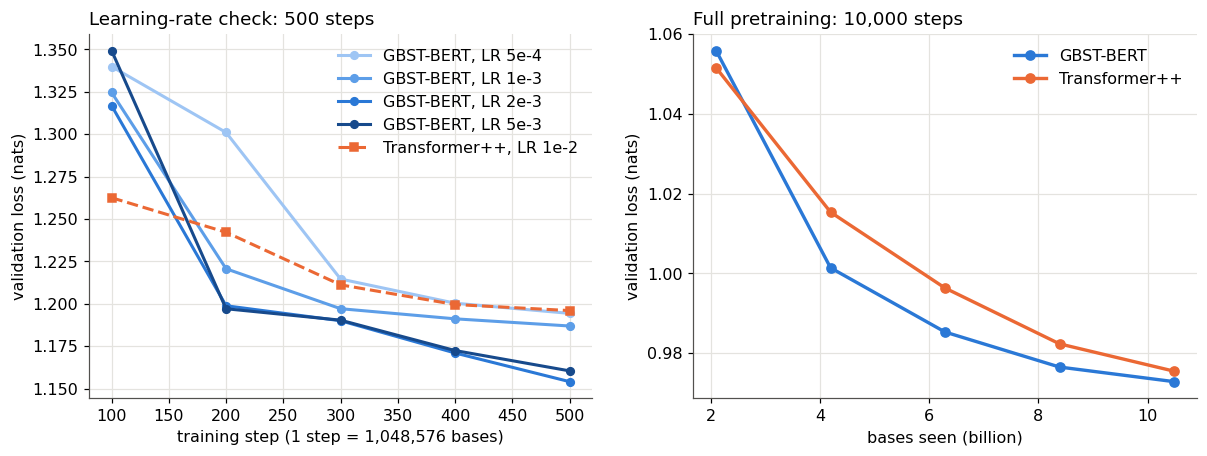

,LR 5e-4,LR 1e-3,LR 2e-3,LR 5e-3
validation loss at step 500,1.1944,1.1869,1.1541,1.1605


,GBST-BERT,Transformer++
"2,000 (2.1 B bases)",1.0559,1.0516
"4,000 (4.2 B bases)",1.0014,1.0153
"6,000 (6.3 B bases)",0.9853,0.9963
"8,000 (8.4 B bases)",0.9765,0.9823
"10,000 (10.5 B bases)",0.9728,0.9755


In [7]:
LR_RUNS = {"5e-4": "small_charna_500", "1e-3": "small_charna_500_lr1e-3",
           "2e-3": "small_charna_500_lr2e-3", "5e-3": "small_charna_500_lr5e-3"}
if RUN_PRETRAINING:
    LR_RUNS = {lr: f"notebook_small_charna_500_lr{lr}" for lr in LR_RUNS}

def metrics(run):
    m = pd.read_csv(PRETRAIN / run / "metrics.csv")
    return m.dropna(subset=["val/loss"])

full = {name: metrics(run) for name, run in MODELS.items()}
# The original GBST-BERT run counted one step ahead after resuming (validation at 4,001 ... 8,001) and
# missed its step-10,000 validation; it was measured afterwards on the final model with the same
# settings (run R21, outputs/full/final_val_charna).
if not RUN_PRETRAINING:
    r21 = pd.read_csv(REPO / "outputs/full/final_val_charna/metrics.csv")
    full["GBST-BERT"] = pd.concat([full["GBST-BERT"],
                                   pd.DataFrame({"global_step": [10000], "val/loss": r21["val/loss"]})])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
ax = axes[0]
shades = ["#9ec5f4", "#5d9ee8", BLUE, "#174a8c"]
for (lr, run), c in zip(LR_RUNS.items(), shades):
    m = metrics(run)
    ax.plot(m.global_step, m["val/loss"], "o-", color=c, lw=2, ms=5, label=f"GBST-BERT, LR {lr}")
if not RUN_PRETRAINING:          # the 500-step Transformer++ run (small experiment, run R10)
    m = metrics("small_llama_500")
    ax.plot(m.global_step, m["val/loss"], "s--", color=ORANGE, lw=2, ms=5, label="Transformer++, LR 1e-2")
ax.set_xlabel("training step (1 step = 1,048,576 bases)"); ax.set_ylabel("validation loss (nats)")
ax.set_title("Learning-rate check: 500 steps"); ax.legend()

ax = axes[1]
for (name, m), c in zip(full.items(), [BLUE, ORANGE]):
    steps = np.round(m.global_step / 1000) * 1000          # 4,001 -> 4,000 (see note above)
    ax.plot(steps * 2 ** 20 / 1e9, m["val/loss"], "o-", color=c, lw=2.2, ms=6, label=name)
ax.set_xlabel("bases seen (billion)"); ax.set_ylabel("validation loss (nats)")
ax.set_title("Full pretraining: 10,000 steps"); ax.legend()
save(fig, "pretraining_curves"); plt.show()

lr_table = pd.DataFrame({f"LR {lr}": [metrics(run)["val/loss"].iloc[-1]] for lr, run in LR_RUNS.items()},
                        index=["validation loss at step 500"])
display(lr_table.style.format("{:.4f}").highlight_min(axis=1, props="font-weight:bold; background:#cfe2f8")
        .set_caption("Learning-rate check (GBST-BERT): lowest = chosen for the full run"))

curve = pd.DataFrame({name: m.assign(step=np.round(m.global_step / 1000) * 1000).set_index("step")["val/loss"]
                      for name, m in full.items()})
curve.index = [f"{int(s):,} ({s * 2 ** 20 / 1e9:.1f} B bases)" for s in curve.index]
display(curve.style.format("{:.4f}").highlight_min(axis=1, props="font-weight:bold; background:#cfe2f8")
        .set_caption("Validation loss during full pretraining (lower is better)"))

## 6. Final test of the pretrained models

The same **2,048 test sequences** (evenly spread over the test split, 1,024 bases each) are
masked in exactly the same way for both models (15% masking as in training, fixed random seed 0),
and each model predicts the hidden bases. This is the repository's `scripts_charna/evaluate_mlm.py`,
run here live. **Accuracy** = the model's best guess among A, C, G, T is the true base.

In [8]:
tokenizer = evaluate_mlm.CaduceusTokenizer(model_max_length=1024)

def final_test(split):
    args = type("Args", (), dict(split=split, bed=str(BED), fasta=str(FASTA), n_seqs=2048, batch=64, seed=0))
    rows = []
    for name, run in MODELS.items():
        model, step = load_repo_model(run)
        row = evaluate_mlm.evaluate(model, evaluate_mlm.masked_batches(args, tokenizer), tokenizer, DEVICE)
        rows.append({"model": name, "step": step, **row})
        del model
    return pd.DataFrame(rows).set_index("model")

start = time.time()
test = final_test("test")
print(f"evaluated in {(time.time() - start) / 60:.1f} min on {int(test.hidden_bases.iloc[0]):,} hidden bases")

show = test[["loss", "acc_ACGT", "acc_A", "acc_C", "acc_G", "acc_T"]].copy()
majority = max("ACGT", key=lambda b: test[f"share_{b}"].iloc[0])
show.loc["Random guess"] = [math.log(4), 0.25, 0.25, 0.25, 0.25, 0.25]
show.loc[f'Always "{majority}" (most common base)'] = [np.nan, test[f"share_{majority}"].iloc[0]] + \
    [1.0 if b == majority else 0.0 for b in "ACGT"]
show.columns = ["test loss (nats)", "accuracy", "acc. A", "acc. C", "acc. G", "acc. T"]
display(show.style.format("{:.4f}", subset=["test loss (nats)"], na_rep="–")
        .format("{:.2%}", subset=["accuracy", "acc. A", "acc. C", "acc. G", "acc. T"])
        .set_caption("Masked-base prediction on 2,048 unseen test sequences"))
show.to_csv(OUT / "final_test.csv")

if not RUN_PRETRAINING:                                  # compare with the original evaluation (run R18)
    saved = pd.read_csv(REPO / "outputs/full/eval_test.csv").set_index("model")
    check = pd.DataFrame({"accuracy now": test.acc_ACGT, "accuracy saved (R18)": saved.acc_ACGT,
                          "loss now": test.loss, "loss saved (R18)": saved.loss})
    display(check.style.format("{:.4%}", subset=["accuracy now", "accuracy saved (R18)"])
            .format("{:.5f}", subset=["loss now", "loss saved (R18)"]).set_caption("Reproduced?"))
    assert np.allclose(check["accuracy now"], check["accuracy saved (R18)"], atol=2e-4)
    assert np.allclose(check["loss now"], check["loss saved (R18)"], atol=2e-4)
    print("reproduced: same accuracy and loss as the original evaluation")

test, dataset length: 1983488


test, dataset length: 1983488


evaluated in 0.2 min on 311,767 hidden bases


,test loss (nats),accuracy,acc. A,acc. C,acc. G,acc. T
model,,,,,,
GBST-BERT,0.9753,56.44%,61.84%,48.50%,48.77%,62.06%
Transformer++,0.9774,56.33%,61.27%,48.89%,48.86%,61.91%
Random guess,1.3863,25.00%,25.00%,25.00%,25.00%,25.00%
"Always ""A"" (most common base)",–,29.42%,100.00%,0.00%,0.00%,0.00%


,accuracy now,accuracy saved (R18),loss now,loss saved (R18)
model,,,,
GBST-BERT,56.4383%,56.4383%,0.97526,0.97526
Transformer++,56.3257%,56.3257%,0.97735,0.97735


reproduced: same accuracy and loss as the original evaluation


## 7. Inside the model

**7.1 Which block sizes did GBST learn to use?** For 8 hg38 sequences from different chromosomes
(15% of bases hidden), we measure GBST's average weight on blocks of 1, 2, 3 and 4 bases, for
models at different stages of training.

,blocks of 1 base,blocks of 2 bases,blocks of 3 bases,blocks of 4 bases
"500 steps, LR 5e-4",72.4%,21.7%,4.9%,1.0%
"500 steps, LR 2e-3",97.6%,2.3%,0.1%,0.0%
"final model (10,000 steps)",98.0%,1.9%,0.1%,0.0%


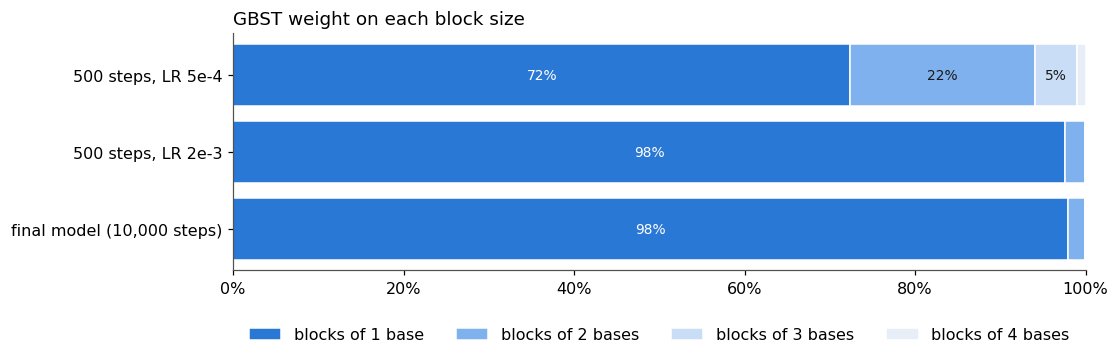

In [9]:
places = [("chr21", 33_000_000), ("chr1", 50_000_000), ("chr7", 117_500_000), ("chr12", 6_500_000),
          ("chr19", 1_000_000), ("chr2", 120_000_000), ("chrX", 70_000_000), ("chr17", 7_670_000)]
seqs = [str(genome[c][p:p + 1024]).upper() for c, p in places]
ids = torch.stack([gbst_bert.encode(s) for s in seqs if "N" not in s])
torch.manual_seed(0)
ids_in = ids.masked_fill(torch.rand(ids.shape) < 0.15, gbst_bert.MASK_ID).to(DEVICE)

stages = {"500 steps, LR 5e-4": LR_RUNS["5e-4"], "500 steps, LR 2e-3": LR_RUNS["2e-3"],
          "final model (10,000 steps)": MODELS["GBST-BERT"]}
weights = {}
for label, run in stages.items():
    m = gbst_bert.load_pretrained(PRETRAIN / run / "checkpoints/last.ckpt").to(DEVICE)
    with torch.no_grad():
        weights[label] = m.backbone.gbst.block_size_weights(ids_in).mean(dim=(0, 1)).cpu().numpy()
block_table = pd.DataFrame(weights, index=[f"blocks of {b} base{'s' if b > 1 else ''}" for b in range(1, 5)]).T
display(block_table.style.format("{:.1%}").set_caption("Share of GBST's weight on each block size"))

fig, ax = plt.subplots(figsize=(10, 2.8))
left = np.zeros(len(block_table))
for b, c in zip(block_table.columns, [BLUE, "#7fb1ee", "#c9ddf6", "#e8eef7"]):
    ax.barh(block_table.index, block_table[b], left=left, color=c, edgecolor="white", label=b)
    for i, v in enumerate(block_table[b]):
        if v > 0.04:
            ax.text(left[i] + v / 2, i, f"{v:.0%}", ha="center", va="center", fontsize=9,
                    color="white" if c == BLUE else TEXT)
    left += block_table[b].values
ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); ax.invert_yaxis(); ax.grid(False)
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.18)); ax.set_title("GBST weight on each block size")
save(fig, "gbst_block_sizes"); plt.show()

**Reading:** early in training GBST still uses longer blocks, but the final model puts almost all
its weight on **single bases**. On human DNA, GBST behaves almost like reading one base at a time
— each base still sees its 3 neighbours through the convolution before the blocks.

**7.2 Where is the model confident?** In a 1,024-base window of chromosome 21 (the first window
from position 33,000,000 on that contains a tandem repeat of ≥ 30 bases), every base is hidden once
(7 passes, every 7th base hidden per pass), and we record the probability the model gives to the
true base.

,bases,guessed right,mean probability of the true base
inside tandem repeats,91,94.5%,88.9%
elsewhere,933,50.8%,43.6%
whole window,1024,54.7%,47.6%


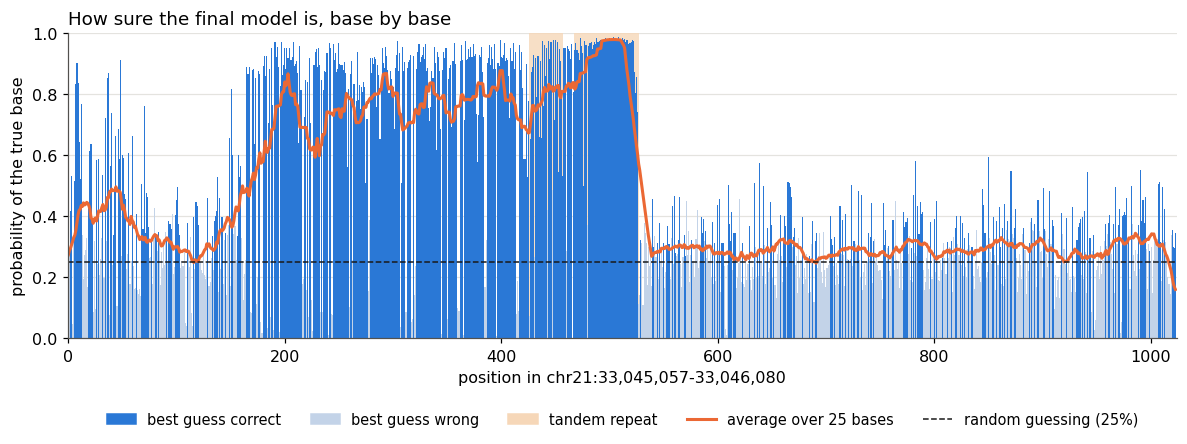

In [10]:
def tandem_repeats(seq, min_len=12):
    # Spans of simple tandem repeats: a unit of 1-6 bases repeated to cover >= min_len bases.
    spans = []
    for period in range(1, 7):
        pattern = r"(?=(([ACGT]{%d})\2{%d,}))" % (period, max(min_len // period - 1, 1))
        for m in re.finditer(pattern, seq):
            if len(m.group(1)) >= min_len:
                spans.append((m.start(), m.start() + len(m.group(1))))
    merged = []
    for s, e in sorted(spans):
        if merged and s <= merged[-1][1]:
            merged[-1] = (merged[-1][0], max(merged[-1][1], e))
        else:
            merged.append((s, e))
    return merged

start = 33_000_000
while True:
    window = str(genome["chr21"][start:start + 1024]).upper()
    if "N" not in window and any(e - s >= 30 for s, e in tandem_repeats(window)):
        break
    start += 1024
repeats = tandem_repeats(window)

final = gbst_bert.load_pretrained(PRETRAIN / MODELS["GBST-BERT"] / "checkpoints/last.ckpt").to(DEVICE)
ids = gbst_bert.encode(window)[None].to(DEVICE)
p_true, correct = np.zeros(1024), np.zeros(1024, bool)
with torch.no_grad():
    for k in range(7):
        hidden = torch.zeros_like(ids, dtype=torch.bool); hidden[0, k::7] = True
        probs = final(ids.masked_fill(hidden, gbst_bert.MASK_ID))[0][:, gbst_bert.BASE_IDS].softmax(-1)
        idx = torch.nonzero(hidden[0]).squeeze(-1)
        p_true[idx.cpu().numpy()] = probs[idx, ids[0, idx] - 7].cpu().numpy()
        correct[idx.cpu().numpy()] = (probs[idx].argmax(-1) == ids[0, idx] - 7).cpu().numpy()
in_repeat = np.zeros(1024, bool)
for s, e in repeats:
    in_repeat[s:e] = True

display(pd.DataFrame({"bases": [in_repeat.sum(), (~in_repeat).sum(), 1024],
                      "guessed right": [correct[in_repeat].mean(), correct[~in_repeat].mean(), correct.mean()],
                      "mean probability of the true base": [p_true[in_repeat].mean(), p_true[~in_repeat].mean(), p_true.mean()]},
                     index=["inside tandem repeats", "elsewhere", "whole window"])
        .style.format({"guessed right": "{:.1%}", "mean probability of the true base": "{:.1%}"})
        .set_caption(f"chr21:{start + 1:,}-{start + 1024:,}; repeats at {repeats}"))

fig, ax = plt.subplots(figsize=(13, 3.6))
for s, e in repeats:
    ax.axvspan(s, e, color="#f6d7b8", alpha=0.8, lw=0)
ax.bar(np.arange(1024), p_true, width=1.0, color=np.where(correct, BLUE, "#c3d3e8"))
smooth = np.convolve(p_true, np.ones(25) / 25, mode="same")
ax.plot(smooth, color=ORANGE, lw=2)
ax.axhline(0.25, color=TEXT, ls="--", lw=1)
from matplotlib.patches import Patch
handles = [Patch(color=BLUE, label="best guess correct"), Patch(color="#c3d3e8", label="best guess wrong"),
           Patch(color="#f6d7b8", label="tandem repeat"), plt.Line2D([], [], color=ORANGE, lw=2, label="average over 25 bases"),
           plt.Line2D([], [], color=TEXT, ls="--", lw=1, label="random guessing (25%)")]
ax.set_xlim(0, 1024); ax.set_ylim(0, 1); ax.set_xlabel(f"position in chr21:{start + 1:,}-{start + 1024:,}")
ax.set_ylabel("probability of the true base")
ax.legend(handles=handles, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.2), fontsize=9.5)
ax.set_title("How sure the final model is, base by base"); ax.grid(axis="x")
save(fig, "confidence_chr21"); plt.show()

## 8. Prediction tasks: the Nucleotide Transformer benchmark

A pretrained model is useful if it helps with biological questions. As in Bio-xLSTM (Table 1),
both models are fine-tuned on the **18 tasks** of the Nucleotide Transformer benchmark
(`InstaDeepAI/nucleotide_transformer_downstream_tasks`): each task asks a yes/no (or which-class)
question about a short DNA piece.

**Protocol** (Bio-xLSTM App. C.5, our script `scripts_downstream/run_nucleotide_charna.sh`):

- the pretrained model + **mean pooling** over positions + a linear layer; the whole model is trained;
- **20 epochs**, the epoch with the best validation score is tested on the task's test set;
- **PH setting**: the training data includes reverse complements, and at test time the prediction
  is averaged over both DNA strands;
- **10 repeats** (seeds) per task; each repeat draws a new training/validation split;
- per task the learning rate and batch size that Bio-xLSTM chose for DNA-xLSTM-PH (Table A5).
  Exception: on splice acceptors and donors these high learning rates made GBST-BERT collapse to
  always predicting one class, so 1e-3 and 5e-4 were also run (3 repeats) and the setting with the
  best mean **validation** score was used (Part 8.3);
- scores as in the paper: MCC (Matthews correlation; 0 = guessing, 1 = perfect) for histone and
  enhancer tasks, F1 for promoters and splice acceptors/donors, accuracy for splice_sites_all.

In [11]:
from datasets import load_dataset

TABLE_A5 = {"H3": ("8e-4", 128), "H3K14ac": ("6e-4", 128), "H3K36me3": ("6e-4", 64), "H3K4me1": ("8e-4", 128),
            "H3K4me2": ("6e-4", 64), "H3K4me3": ("8e-4", 128), "H3K79me3": ("1e-3", 128), "H3K9ac": ("4e-4", 64),
            "H4": ("8e-4", 64), "H4ac": ("4e-4", 64), "enhancers": ("2e-3", 512), "enhancers_types": ("2e-3", 512),
            "promoter_all": ("4e-4", 64), "promoter_no_tata": ("1e-3", 128), "promoter_tata": ("3e-3", 128),
            "splice_sites_all": ("8e-4", 64), "splice_sites_acceptors": ("2e-3", 128), "splice_sites_donors": ("3e-3", 128)}
TASKS = list(TABLE_A5)
METRIC = {t: "MCC" for t in TASKS[:12]} | {t: "F1" for t in TASKS[12:]} | {"splice_sites_all": "accuracy"}
GROUP = {t: "histone mark" for t in TASKS[:10]} | {t: "enhancer" for t in TASKS[10:12]} | \
        {t: "promoter" for t in TASKS[12:15]} | {t: "splice site" for t in TASKS[15:]}

rows = []
for task in TASKS:
    data = {split: load_dataset("InstaDeepAI/nucleotide_transformer_downstream_tasks",
                                data_files={split: f"{task}/{split}.parquet"}, split=split) for split in ("train", "test")}
    rows.append({"task": task, "group": GROUP[task], "classes": len(set(data["train"]["label"])),
                 "length (bases)": len(data["train"][0]["sequence"]), "train sequences": len(data["train"]),
                 "test sequences": len(data["test"]), "score": METRIC[task],
                 "learning rate (A5)": TABLE_A5[task][0], "batch (A5)": TABLE_A5[task][1]})
display(pd.DataFrame(rows).set_index("task").style.format({"train sequences": "{:,}", "test sequences": "{:,}"})
        .set_caption("The 18 tasks (sequence length of the first training example)"))

,group,classes,length (bases),train sequences,test sequences,score,learning rate (A5),batch (A5)
task,,,,,,,,
H3,histone mark,2,500,"13,468","1,497",MCC,8e-4,128
H3K14ac,histone mark,2,500,"29,743","3,305",MCC,6e-4,128
H3K36me3,histone mark,2,500,"31,392","3,488",MCC,6e-4,64
H3K4me1,histone mark,2,500,"28,509","3,168",MCC,8e-4,128
H3K4me2,histone mark,2,500,"27,614","3,069",MCC,6e-4,64
H3K4me3,histone mark,2,500,"33,119","3,680",MCC,8e-4,128
H3K79me3,histone mark,2,500,"25,953","2,884",MCC,1e-3,128
H3K9ac,histone mark,2,500,"25,003","2,779",MCC,4e-4,64
H4,histone mark,2,500,"13,140","1,461",MCC,8e-4,64


### 8.1 Re-running one fine-tuning job

With `RUN_ONE_FINETUNE = True` the notebook fine-tunes GBST-BERT on task **H3, repeat 1** again,
with exactly the command used in the benchmark, into a separate folder, and compares the test
score with the original run. (GPU arithmetic is not bit-for-bit deterministic, so a small
difference is possible.) With `RUN_NT_BENCHMARK = True` the complete benchmark runs again
(`scripts_charna/server/run_nt_benchmark.sh`, 10 repeats, into `outputs/downstream/nt_notebook`).

In [12]:
def nt_command(model, task, lr, batch, seed, out_root, gpu):
    return (f"CUDA_VISIBLE_DEVICES={gpu} MODEL={model} PRETRAIN_DIR=../outputs/pretrain/hg38/full_{model}_mlm "
            f"PRETRAINED_PATH={PRETRAIN}/full_{model}_mlm/checkpoints/last.ckpt TASKS={task} LRS={lr} "
            f"BATCH_SIZES={batch} SEEDS={seed} NUM_WORKERS=4 OUT_ROOT={out_root} bash run_nucleotide_charna.sh")

def run_scores(metrics_csv):
    # (best validation score, test score at the best validation epoch) of one fine-tuning run
    m = pd.read_csv(metrics_csv)
    test_col = [c for c in m.columns if c.startswith("test/") and c != "test/loss"]
    val_col = [c for c in m.columns if c.startswith("val/") and c != "val/loss"][0]
    if not test_col or m[test_col[0]].dropna().empty:
        return None
    return m[val_col].dropna().max(), m[test_col[0]].dropna().iloc[-1]

if RUN_ONE_FINETUNE:
    lr, batch = TABLE_A5["H3"]
    shell(nt_command("charna", "H3", lr, batch, 1, "./outputs/downstream/nt_notebook_rerun", GPU),
          OUT / "finetune_H3_seed1.log", cwd=REPO / "scripts_downstream", env={"CUDA_VISIBLE_DEVICES": GPU})
    rel = f"H3/full_charna_mlm_ph/LR-{lr}_BATCH_SIZE-{batch}/seed-1/metrics.csv"
    new = run_scores(REPO / "outputs/downstream/nt_notebook_rerun" / rel)
    old = run_scores(NT_RESULTS / rel)
    display(pd.DataFrame({"best validation MCC": [new[0], old[0]], "test MCC": [new[1], old[1]]},
                         index=["re-run now", "original run"]).style.format("{:.4f}")
            .set_caption("GBST-BERT, task H3, repeat 1"))
    print(f"difference in test MCC: {new[1] - old[1]:+.4f} (GPU training is not bit-for-bit deterministic; "
          f"the 10 original repeats of this task range from "
          f"{min(s for _, s in [run_scores(f) for f in (NT_RESULTS / 'H3/full_charna_mlm_ph' / f'LR-{lr}_BATCH_SIZE-{batch}').glob('seed-*/metrics.csv')]):.3f} to "
          f"{max(s for _, s in [run_scores(f) for f in (NT_RESULTS / 'H3/full_charna_mlm_ph' / f'LR-{lr}_BATCH_SIZE-{batch}').glob('seed-*/metrics.csv')]):.3f})")

if RUN_NT_BENCHMARK:
    shell(f"GPUS='{TRAIN_GPUS.replace(',', ' ')}' NT_OUT_ROOT=./outputs/downstream/nt_notebook "
          f"OUT_DIR={REPO}/outputs/downstream/nt_queue_notebook bash run_nt_benchmark.sh '1 2 3' && "
          f"GPUS='{TRAIN_GPUS.replace(',', ' ')}' NT_OUT_ROOT=./outputs/downstream/nt_notebook "
          f"OUT_DIR={REPO}/outputs/downstream/nt_queue_notebook NT_TABLE=nt_tables/final_settings.txt "
          f"bash run_nt_benchmark.sh '4 5 6 7 8 9 10' && "
          f"GPUS='{TRAIN_GPUS.replace(',', ' ')}' NT_OUT_ROOT=./outputs/downstream/nt_notebook "
          f"OUT_DIR={REPO}/outputs/downstream/nt_queue_notebook NT_TABLE=nt_tables/splice_lr_check.txt "
          f"bash run_nt_benchmark.sh '1 2 3'", OUT / "nt_benchmark.log",
          cwd=REPO / "scripts_charna/server")
    NT_RESULTS = REPO / "outputs/downstream/nt_notebook"

finished in 0.0 min, exit code 0, log: /system/user/omohamed/charna/dna-xlstm/notebooks/outputs/finetune_H3_seed1.log


,best validation MCC,test MCC
re-run now,0.8374,0.8362
original run,0.8317,0.8323


difference in test MCC: +0.0039 (GPU training is not bit-for-bit deterministic; the 10 original repeats of this task range from 0.802 to 0.832)


### 8.2 Collecting all runs

Every fine-tuning run wrote a `metrics.csv` with its validation score after each epoch and the
test score of the best epoch. For each task and model, the setting (learning rate, batch) with
the most finished repeats and then the best mean validation score is used — the test set never
decides anything.

In [13]:
OURS = {"GBST-BERT": "full_charna_mlm_ph", "Transformer++": "full_llama_mlm_ph"}

def collect(task, folder):
    settings = {}
    for config in sorted((NT_RESULTS / task / folder).glob("LR-*")):
        files = sorted(config.glob("seed-*/metrics.csv"), key=lambda f: int(f.parent.name.split("-")[1]))
        runs = [s for s in map(run_scores, files) if s]
        if runs:
            settings[config.name] = runs
    n = max(len(r) for r in settings.values())
    best = max((c for c in settings if len(settings[c]) == n), key=lambda c: np.mean([v for v, _ in settings[c]]))
    return best, [t for _, t in settings[best]], settings

ours, all_settings = {}, {}
for task in TASKS:
    for name, folder in OURS.items():
        setting, scores, settings = collect(task, folder)
        ours[(task, name)] = {"setting": setting, "scores": scores}
        all_settings[(task, name)] = settings
n_runs = sum(len(r) for s in all_settings.values() for r in s.values())
print(f"{n_runs} fine-tuning runs found in {NT_RESULTS.relative_to(REPO)}")
print("repeats per task and model:", sorted({len(v['scores']) for v in ours.values()}))

384 fine-tuning runs found in outputs/downstream/nt_cv10_ep20
repeats per task and model: [10]


### 8.3 The splice-site learning-rate check

For the two splice tasks, the paper's learning rates (2e-3, 3e-3) and two smaller ones were run
(3 repeats each). The table shows the mean **validation** score (used to choose) and, for
information, the mean test score.

In [14]:
rows = []
for task in ["splice_sites_acceptors", "splice_sites_donors"]:
    for name in OURS:
        for setting, runs in all_settings[(task, name)].items():
            runs = runs[:3]                                  # the first 3 repeats, equal for all settings
            rows.append({"task": task, "model": name, "learning rate": setting.split("_")[0][3:],
                         "mean validation F1": np.mean([v for v, _ in runs]),
                         "mean test F1": np.mean([t for _, t in runs]),
                         "lowest test F1": np.min([t for _, t in runs]),
                         "chosen": "✓ chosen" if setting == ours[(task, name)]["setting"] else ""})
display(pd.DataFrame(rows).set_index(["task", "model", "learning rate"]).style
        .format({"mean validation F1": "{:.3f}", "mean test F1": "{:.3f}", "lowest test F1": "{:.3f}"})
        .set_caption("Splice tasks: repeats 1-3 at each learning rate (F1 ≈ 0.66 = always one class)"))

## 9. Results compared with the Bio-xLSTM paper

The five comparison models (HyenaDNA, Mamba and xLSTM, each in the PS or PH variant) are the
values of **Bio-xLSTM Table 1** (mean and max − min over 10 seeds), stored in
`notebooks/bioxlstm_table1_nt.csv`.

In [15]:
paper = pd.read_csv(REPO / "notebooks/bioxlstm_table1_nt.csv").set_index("task")
PAPER_MODELS = ["HyenaDNA", "Mamba-PS", "Mamba-PH", "xLSTM-PS", "xLSTM-PH"]
ALL = PAPER_MODELS + list(OURS)

mean = pd.DataFrame({m: paper[f"{m} mean"] for m in PAPER_MODELS}).loc[TASKS]
spread = pd.DataFrame({m: paper[f"{m} range"] for m in PAPER_MODELS}).loc[TASKS]
for name in OURS:
    mean[name] = [np.mean(ours[(t, name)]["scores"]) for t in TASKS]
    spread[name] = [np.ptp(ours[(t, name)]["scores"]) for t in TASKS]
best = mean.max(axis=1)
is_best = mean.ge(best - 5e-4, axis=0)
wins = is_best.sum()

table = pd.DataFrame({m: [f"{a:.3f} ± {b:.3f}" for a, b in zip(mean[m], spread[m])] for m in ALL}, index=TASKS)
table.insert(0, "score", [METRIC[t] for t in TASKS])
table.loc["Tasks with the best mean"] = [""] + [str(int(wins[m])) for m in ALL]

def highlight(df):
    style = pd.DataFrame("", index=df.index, columns=df.columns)
    for m in ALL:
        style.loc[TASKS, m] = np.where(is_best.loc[TASKS, m], "font-weight:bold; background:#cfe2f8", "")
    style.loc["Tasks with the best mean"] = "font-weight:bold; border-top:2px solid #333"
    return style
display(table.style.apply(highlight, axis=None)
        .set_caption("Test score, mean ± (max − min) over 10 repeats; highlighted = best mean "
                     "(within 0.0005, ties counted for each). Higher is better."))
mean.to_csv(OUT / "nt_means.csv"); spread.to_csv(OUT / "nt_ranges.csv"); table.to_csv(OUT / "nt_table.csv")

better_than_control = int((mean["GBST-BERT"] > mean["Transformer++"] + 5e-4).sum())
display(Markdown(f"**GBST-BERT has the best mean on {int(wins['GBST-BERT'])} of 18 tasks** "
                 f"(xLSTM-PH {int(wins['xLSTM-PH'])}, Mamba-PH {int(wins['Mamba-PH'])}, Mamba-PS "
                 f"{int(wins['Mamba-PS'])}), and beats the same model without GBST (Transformer++) on "
                 f"**{better_than_control} of 18**."))

,score,HyenaDNA,Mamba-PS,Mamba-PH,xLSTM-PS,xLSTM-PH,GBST-BERT,Transformer++
H3,MCC,0.779 ± 0.037,0.799 ± 0.029,0.815 ± 0.048,0.796 ± 0.014,0.824 ± 0.010,0.815 ± 0.031,0.801 ± 0.029
H3K14ac,MCC,0.612 ± 0.065,0.541 ± 0.212,0.631 ± 0.026,0.570 ± 0.008,0.598 ± 0.017,0.673 ± 0.016,0.569 ± 0.062
H3K36me3,MCC,0.613 ± 0.041,0.609 ± 0.109,0.601 ± 0.129,0.588 ± 0.019,0.625 ± 0.010,0.655 ± 0.035,0.591 ± 0.032
H3K4me1,MCC,0.512 ± 0.024,0.488 ± 0.102,0.523 ± 0.039,0.490 ± 0.012,0.526 ± 0.001,0.565 ± 0.038,0.481 ± 0.037
H3K4me2,MCC,0.455 ± 0.095,0.388 ± 0.101,0.487 ± 0.170,0.489 ± 0.024,0.504 ± 0.012,0.509 ± 0.212,0.367 ± 0.076
H3K4me3,MCC,0.549 ± 0.056,0.440 ± 0.202,0.544 ± 0.045,0.520 ± 0.019,0.537 ± 0.012,0.553 ± 0.180,0.362 ± 0.219
H3K79me3,MCC,0.672 ± 0.048,0.676 ± 0.026,0.697 ± 0.077,0.662 ± 0.011,0.697 ± 0.007,0.697 ± 0.132,0.676 ± 0.041
H3K9ac,MCC,0.581 ± 0.061,0.604 ± 0.048,0.622 ± 0.030,0.622 ± 0.013,0.627 ± 0.008,0.648 ± 0.037,0.599 ± 0.046
H4,MCC,0.763 ± 0.044,0.789 ± 0.020,0.811 ± 0.022,0.793 ± 0.011,0.813 ± 0.008,0.804 ± 0.074,0.803 ± 0.022
H4ac,MCC,0.564 ± 0.038,0.525 ± 0.240,0.621 ± 0.054,0.558 ± 0.018,0.583 ± 0.014,0.642 ± 0.037,0.528 ± 0.036


**GBST-BERT has the best mean on 13 of 18 tasks** (xLSTM-PH 4, Mamba-PH 2, Mamba-PS 1), and beats the same model without GBST (Transformer++) on **16 of 18**.

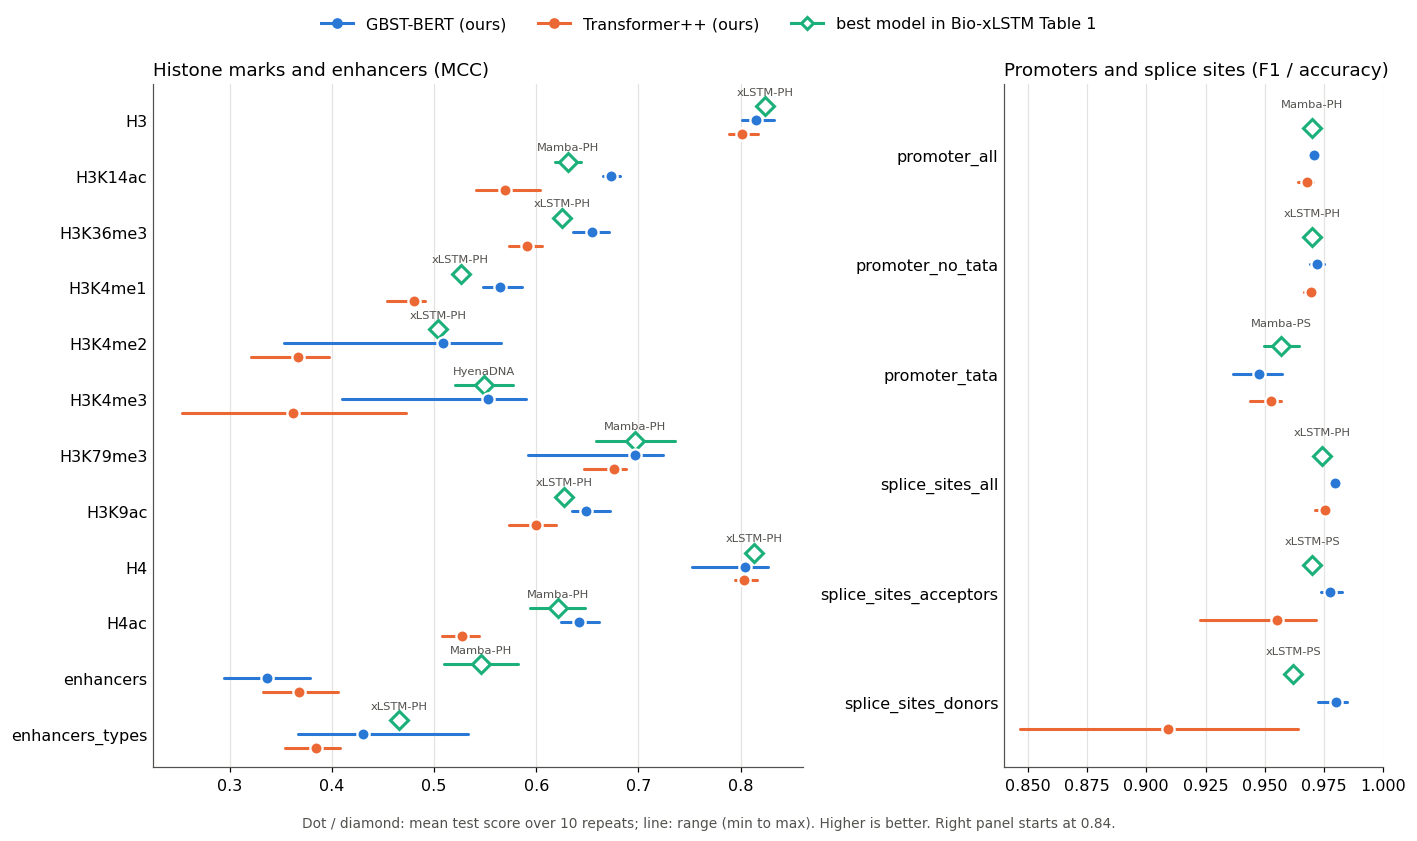

In [16]:
# Figure 1: every task, our two models next to the best paper model (mean and range over repeats)
groups = [[t for t in TASKS if METRIC[t] == "MCC"], [t for t in TASKS if METRIC[t] != "MCC"]]
fig, axes = plt.subplots(1, 2, figsize=(13, 7.5), gridspec_kw={"width_ratios": [12, 7]})
for ax, tasks, title in zip(axes, groups, ["Histone marks and enhancers (MCC)",
                                           "Promoters and splice sites (F1 / accuracy)"]):
    for i, task in enumerate(tasks):
        y = len(tasks) - 1 - i
        top = mean.loc[task, PAPER_MODELS].idxmax()
        m, r = mean.loc[task, top], spread.loc[task, top]
        ax.plot([m - r / 2, m + r / 2], [y + 0.25] * 2, color=GREEN, lw=2, solid_capstyle="round")
        ax.plot(m, y + 0.25, "D", ms=8, mfc="white", mec=GREEN, mew=2)
        ax.text(m, y + 0.42, top, fontsize=7.5, color=MUTED, ha="center", va="bottom")
        for name, dy, c in [("GBST-BERT", 0, BLUE), ("Transformer++", -0.25, ORANGE)]:
            s = ours[(task, name)]["scores"]
            ax.plot([min(s), max(s)], [y + dy] * 2, color=c, lw=2, solid_capstyle="round")
            ax.plot(np.mean(s), y + dy, "o", ms=8, color=c, mec="white", mew=1.5)
    ax.set_yticks(range(len(tasks)), list(reversed(tasks))); ax.set_ylim(-0.6, len(tasks) - 0.35)
    ax.set_title(title); ax.grid(axis="y", visible=False); ax.tick_params(axis="y", length=0)
axes[1].set_xlim(0.84, 1.0)
handles = [plt.Line2D([], [], color=BLUE, marker="o", lw=2, label="GBST-BERT (ours)"),
           plt.Line2D([], [], color=ORANGE, marker="o", lw=2, label="Transformer++ (ours)"),
           plt.Line2D([], [], color=GREEN, marker="D", mfc="white", mew=2, lw=2, label="best model in Bio-xLSTM Table 1")]
fig.legend(handles=handles, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.0))
fig.text(0.5, 0.0, "Dot / diamond: mean test score over 10 repeats; line: range (min to max). Higher is better. "
         "Right panel starts at 0.84.", ha="center", fontsize=9, color=MUTED)
fig.tight_layout(rect=(0, 0.02, 1, 0.95)); save(fig, "nt_all_tasks"); plt.show()

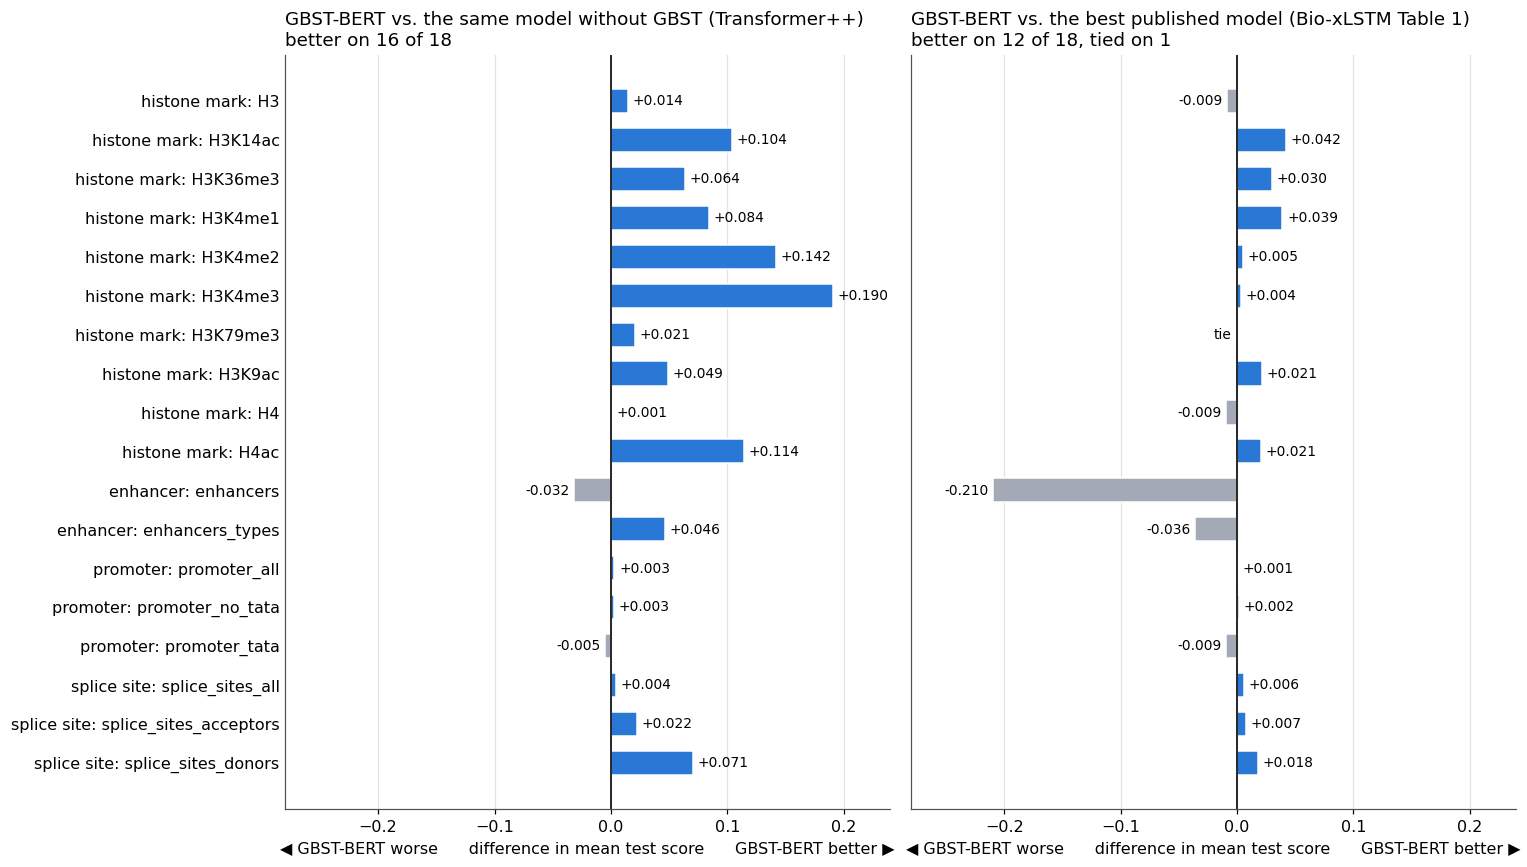

In [17]:
# Figure 2: the same results as differences: how much better or worse is GBST-BERT?
labels = [f"{GROUP[t]}: {t}" for t in TASKS]
panels = [("vs. the same model without GBST (Transformer++)", mean["GBST-BERT"] - mean["Transformer++"]),
          ("vs. the best published model (Bio-xLSTM Table 1)", mean["GBST-BERT"] - mean[PAPER_MODELS].max(axis=1))]
fig, axes = plt.subplots(1, 2, figsize=(14, 8), sharey=True)
for ax, (title, diff) in zip(axes, panels):
    y = np.arange(len(TASKS))[::-1]
    colors = [BLUE if d > 5e-4 else GREY for d in diff]
    ax.barh(y, diff, color=colors, height=0.62, edgecolor="white")
    for yi, d in zip(y, diff):
        ax.text(d + (0.004 if d >= 0 else -0.004), yi, "tie" if abs(d) <= 5e-4 else f"{d:+.3f}",
                va="center", ha="left" if d >= 0 else "right", fontsize=9)
    n_better, n_tie = int((diff > 5e-4).sum()), int((diff.abs() <= 5e-4).sum())
    ax.axvline(0, color=TEXT, lw=1.2); ax.set_xlim(-0.28, 0.24); ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0)
    ax.set_title(f"GBST-BERT {title}\nbetter on {n_better} of 18" + (f", tied on {n_tie}" if n_tie else ""))
    ax.set_xlabel("◀ GBST-BERT worse      difference in mean test score      GBST-BERT better ▶")
axes[0].set_yticks(np.arange(len(TASKS))[::-1], labels); axes[0].tick_params(axis="y", length=0)
fig.tight_layout(); save(fig, "nt_differences"); plt.show()

## 10. Summary

In [18]:
acc = test["acc_ACGT"]; loss = test["loss"]
summary = f'''
**Pretraining (Parts 5-6).** Both 2-million-parameter models learned human DNA: on 2,048 unseen
test sequences GBST-BERT guesses **{acc['GBST-BERT']:.2%}** of hidden bases correctly (loss
{loss['GBST-BERT']:.4f}) and Transformer++ **{acc['Transformer++']:.2%}** (loss {loss['Transformer++']:.4f});
random guessing gives 25% (loss 1.386). The difference is too small to call from one run per model.

**Inside the model (Part 7).** GBST learned to put {block_table.iloc[-1, 0]:.0%} of its weight on
single bases; the model is very sure inside tandem repeats ({correct[in_repeat].mean():.0%} right)
and much less elsewhere ({correct[~in_repeat].mean():.0%}).

**Prediction tasks (Parts 8-9).** Over 18 tasks with 10 repeats each, GBST-BERT has the best mean
of all seven models on **{int(wins['GBST-BERT'])} tasks** and beats the same model without GBST on
**{better_than_control} of 18**. It is strongest on splice sites and histone marks and weakest on
enhancers.

**Not yet shown:** which part of GBST causes the gain (the two models also differ in normalisation);
the clean test is the same model with GBST replaced by a lookup table (`TOKENIZER=embedding`).

All tables and figures of this notebook are in `notebooks/outputs/`.
'''
display(Markdown(summary))


**Pretraining (Parts 5-6).** Both 2-million-parameter models learned human DNA: on 2,048 unseen
test sequences GBST-BERT guesses **56.44%** of hidden bases correctly (loss
0.9753) and Transformer++ **56.33%** (loss 0.9774);
random guessing gives 25% (loss 1.386). The difference is too small to call from one run per model.

**Inside the model (Part 7).** GBST learned to put 98% of its weight on
single bases; the model is very sure inside tandem repeats (95% right)
and much less elsewhere (51%).

**Prediction tasks (Parts 8-9).** Over 18 tasks with 10 repeats each, GBST-BERT has the best mean
of all seven models on **13 tasks** and beats the same model without GBST on
**16 of 18**. It is strongest on splice sites and histone marks and weakest on
enhancers.

**Not yet shown:** which part of GBST causes the gain (the two models also differ in normalisation);
the clean test is the same model with GBST replaced by a lookup table (`TOKENIZER=embedding`).

All tables and figures of this notebook are in `notebooks/outputs/`.
